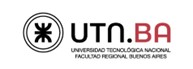

###**Trabajo Practico de Laboratorio 2**
**Teoria de los Circuitos 2**


Autor: Alan Nicolas Parizek

Integrantes: Alan Nicolas Parizek,
             Matias Marchesi,
             Martin Silvosa


Profesor: Mariano Llamedo Soria  
Ayudante de TPs: David Moharos  
Jefe de TPs: César Fuoco  




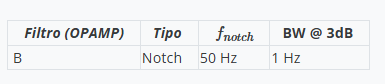

In [1]:
# Inicialización e importación de módulos

# Módulos para Jupyter
import warnings
warnings.filterwarnings('ignore')

# Módulos importantantes
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import scipy.io as sio
from pytc2.sistemas_lineales import plot_plantilla

# Tamaño de las figuras
fig_sz_x = 14
fig_sz_y = 7

# Tamaño de la tipografía
fig_font_size = 16

plt.rcParams.update({'font.size':fig_font_size})

###
## Señal de ECG registrada a 1 kHz, con contaminación de diversos orígenes.
###

# para listar las variables que hay en el archivo
#io.whosmat('ecg.mat')
#mat_struct = sio.loadmat('ecg.mat')

#ecg_one_lead = mat_struct['ecg_lead']
#ecg_one_lead = ecg_one_lead.flatten()
#cant_muestras = len(ecg_one_lead)

fs = 1000 # Hz
nyq_frec = fs / 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np

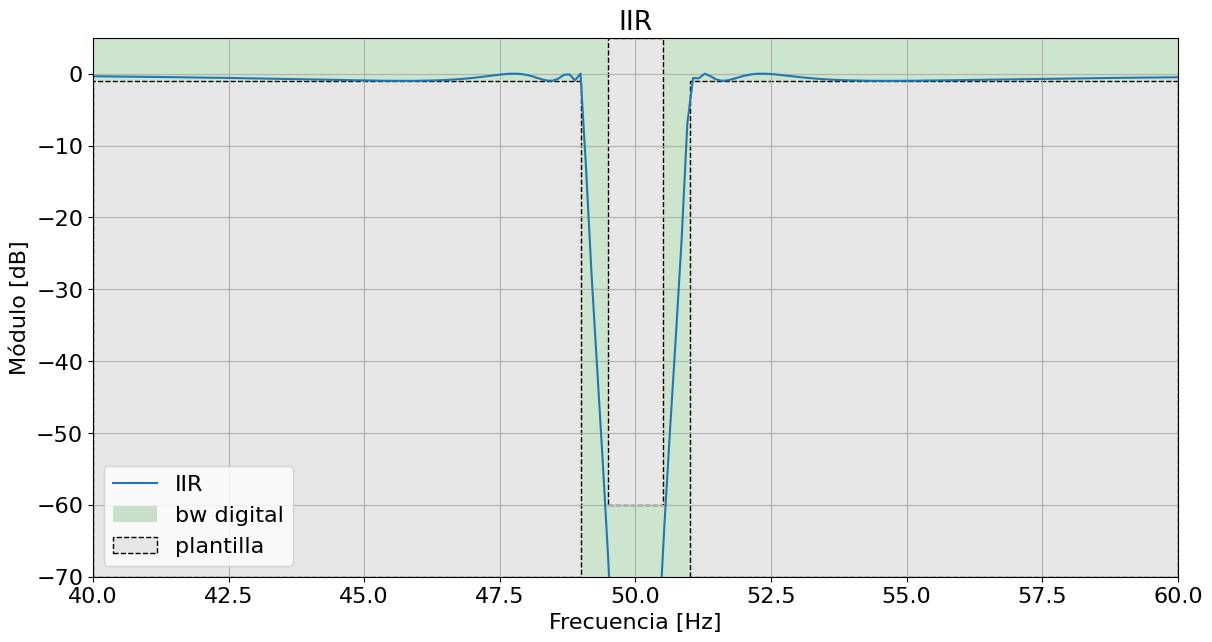

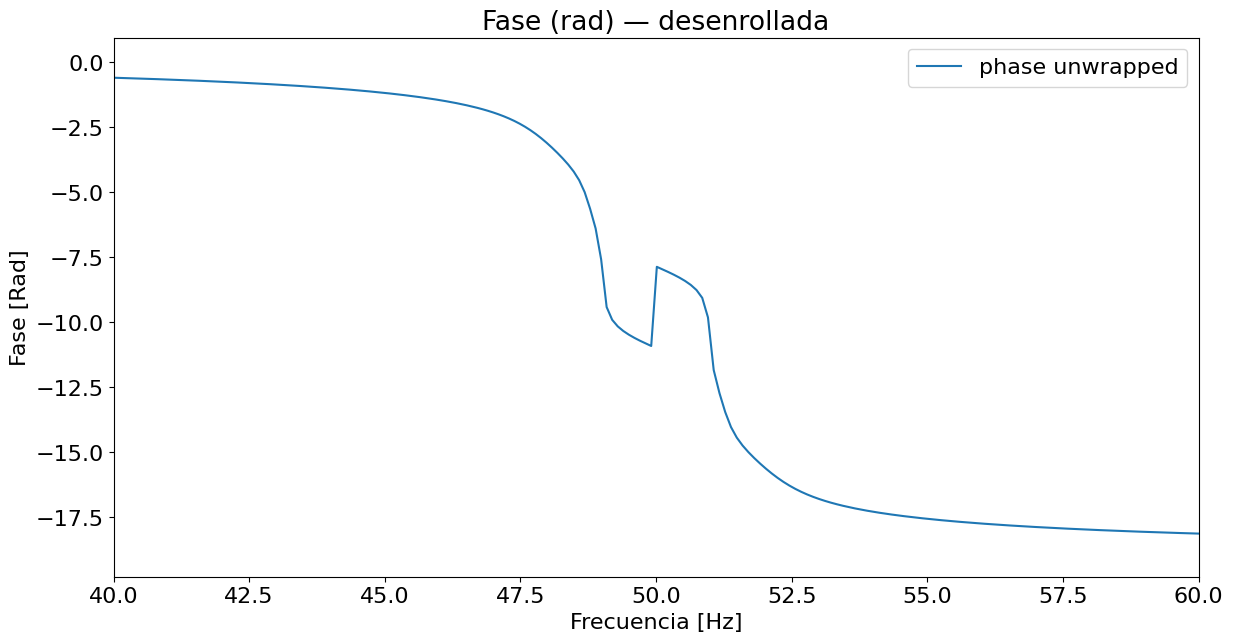

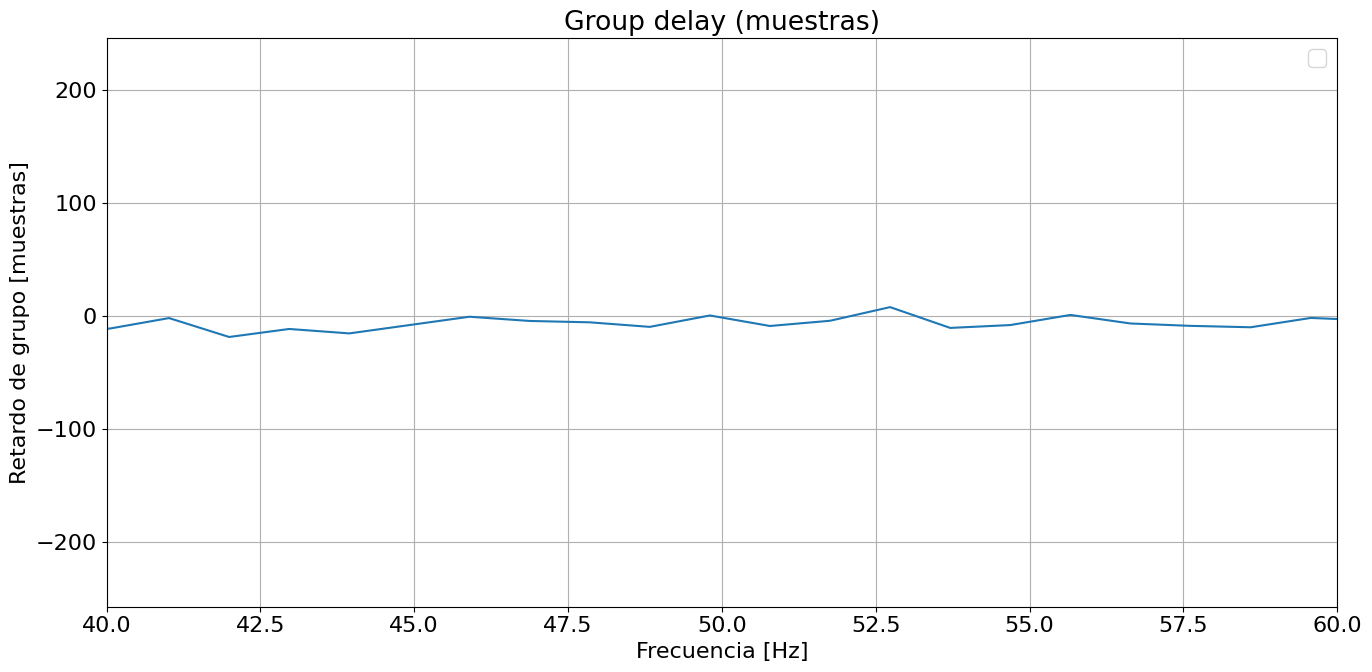

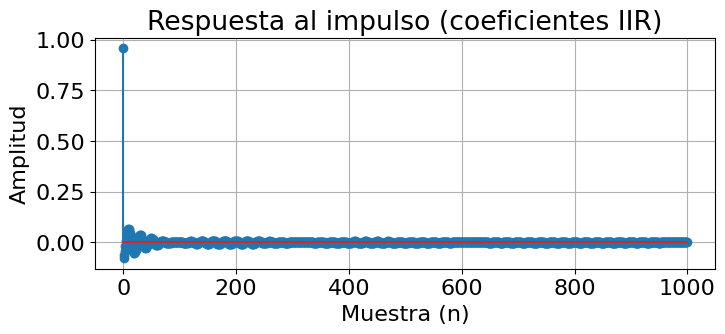

In [8]:
# Variables
ripple = 1 # dB
atenuacion = 60 # dB

ws1 = 49.5 #Hz
wp1 = 49 #Hz
wp2 = 51.0 #Hz
ws2 = 50.5 #Hz

ripple_iterado = 1 # dB
atenuacion_iterado = 60 # dB

sos_iir = sig.iirdesign(wp=[wp1,wp2],ws=[ws1,ws2],gpass=ripple_iterado, gstop=atenuacion_iterado, output='sos', analog=False, ftype='cheby1', fs = fs)

w_rad  = np.append(np.logspace(-3, 0.8, 1000), np.logspace(0.9, 1.8, 1000) )
w_rad  = np.append(w_rad, np.linspace(64, nyq_frec, 1000, endpoint=True) )

w_rad, h_iir = sig.freqz_sos(sos_iir, worN=w_rad, fs = fs)

phase = np.angle(h_iir)
phase_unwrapped = np.unwrap(phase)

#%matplotlib qt

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w_rad, 20*np.log10(np.abs(h_iir)+1e-12), label = 'IIR' )

plt.title('IIR')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([40, 60, -70, 5 ]);

axes_hdl = plt.gca()

plot_plantilla(filter_type = 'bandstop', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)
_ = axes_hdl.legend()
plt.show()

b_iir, a_iir = sig.sos2tf(sos_iir)  # convierte SOS a b, a
w_gd, gd = sig.group_delay((b_iir, a_iir), fs=fs)

mag_db = 20 * np.log10(abs(h_iir))

phase = np.angle(h_iir)
phase_unwrapped = np.unwrap(phase)

pb_idx = np.where(mag_db > -40)[0]
if pb_idx.size > 10:
    # ajustar fase_unwrapped vs frecuencia (Hz): phase = -2*pi*f*delay + const
    p = np.polyfit(w_rad[pb_idx], phase_unwrapped[pb_idx], 1)
    slope = p[0]
    est_delay_from_phase = -slope / (2 * np.pi)   # en muestras
else:
    est_delay_from_phase = np.nan

imp = np.zeros(1000)  # tamaño deseado
imp[0] = 1.0
h_iir_imp = sig.sosfilt(sos_iir, imp)

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))
plt.plot(w_rad, phase_unwrapped, label='phase unwrapped')
plt.title('Fase (rad) — desenrollada')

plt.xlabel('Frecuencia [Hz]')
plt.xlim(40, 60)
plt.ylabel('Fase [Rad]')
plt.grid()
#plt.axis([0, 60, -60, 5 ]);
plt.legend()

axes_hdl = plt.gca()
axes_hdl.legend()
plt.grid()
_ = plt.legend()
plt.show()

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))
plt.plot(w_gd, gd)
plt.title('Group delay (muestras)')
plt.xlim(40, 60)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Retardo de grupo [muestras]')

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

#axes_hdl = plt.gca()
#axes_hdl.legend()
# plt.grid()
# _ = plt.legend()

# Impulso (stem)
plt.figure(figsize=(8,3))
plt.stem(h_iir_imp)
plt.title('Respuesta al impulso (coeficientes IIR)')
plt.xlabel("Muestra (n)")
plt.ylabel("Amplitud")
plt.grid()
plt.show()

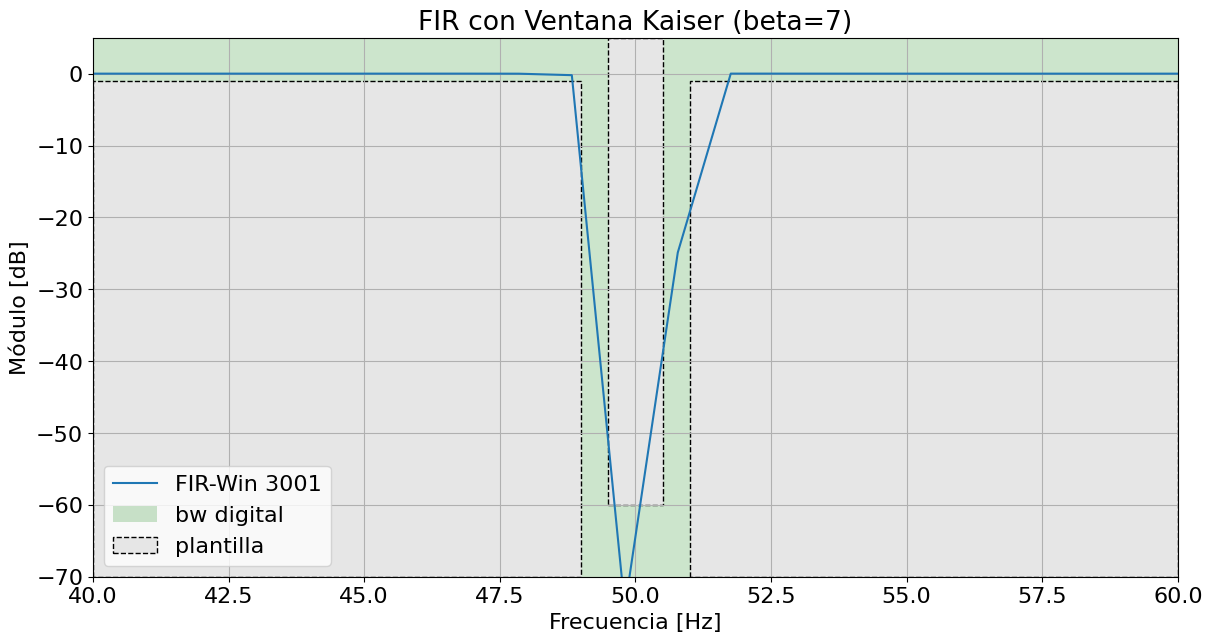

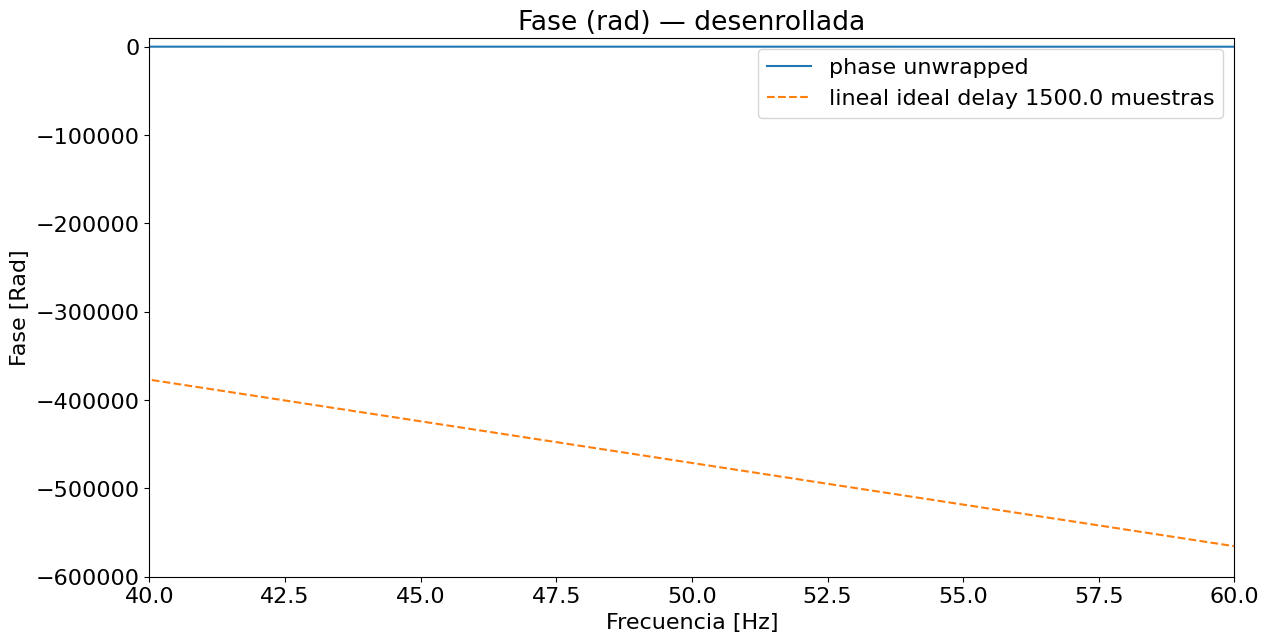

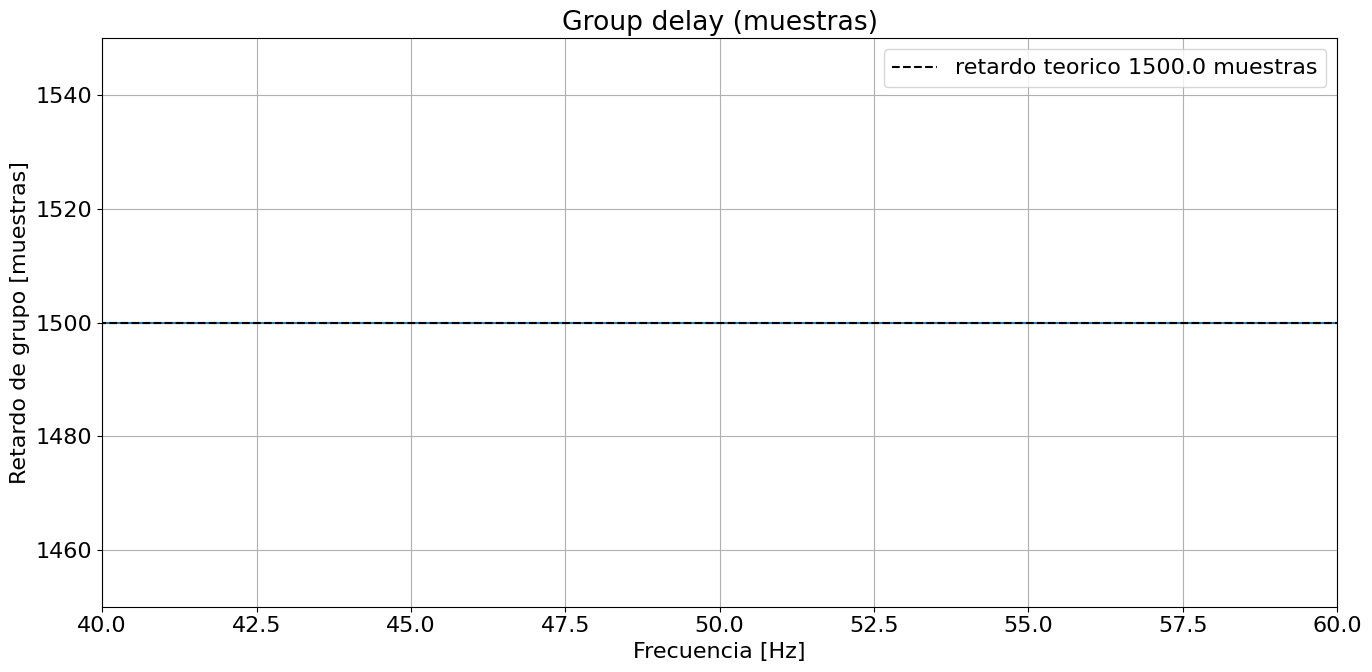

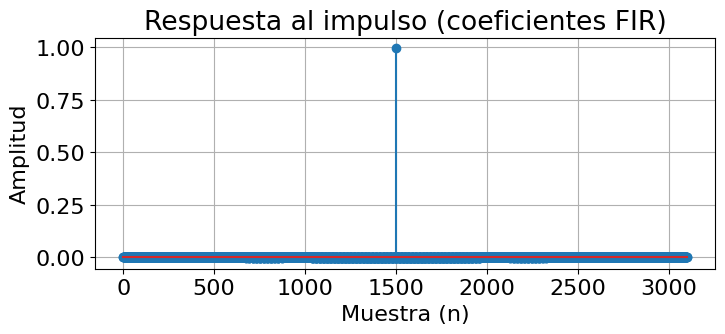

In [9]:
# plt.close('all')

# se fija una cantidad de coeficientes para la respuesta del FIR
cant_coeficientes = 3001 # 1501 default

# variables

# default: wp1=.1Hz , ws1=1Hz , wp2=35Hz , ws2=45Hz

# Define frequencies for a 50Hz notch with 1Hz bandwidth (adjusted for stricter compliance)
# Based on plantilla: wp1=49, wp2=51.0 (passband edges), ws1=49.5, ws2=50.5 (stopband edges)
# Added 4 intermediate frequencies with gain 0 to ensure 60dB attenuation.
frecuencias = [0, 48.2, 49.2, 49.3, 49.4, 49.5, 49.6, 49.7, 49.8, 49.9, 50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50.7, 50.8, 50.9, 51.0, 51.1, 51.2, 52.2, nyq_frec]

ganancia = [1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1] # Strict pass/stop gain values for 60dB attenuation

#ventana = ('chebwin', 80)

#ventana = 'bohman'

#ventana = 'blackman'

#ventana = 'cosine'

#ventana = 'taylor'

ventana = ('kaiser', 5)

#ventana = 'hamming'

# algoritmo de diseño, se obtienen los coeficientes del numerador
num_win = sig.firwin2(cant_coeficientes, freq = frecuencias, gain = ganancia , window= ventana , fs = fs )
# default window = 'blackmanharris' ^^

# coeficientes del denominador
den = 1.0

# muestreo el filtro donde me interesa verlo según la plantilla.
#w  = np.append(np.logspace(-1, 0.8, 250), np.logspace(0.9, 1.6, 250) )
#w  = np.append(w, np.linspace(110, nyq_frec, 100, endpoint=True) )


w, hh_win = sig.freqz(num_win, den, fs = fs)

w_gd, gd = sig.group_delay((num_win, den), w=w, fs=fs)  # gd en muestras
retardo_teorico = (cant_coeficientes - 1) / 2

mag_db = 20 * np.log10(abs(hh_win))

phase = np.angle(hh_win)
phase_unwrapped = np.unwrap(phase)

pb_idx = np.where(mag_db > -40)[0]
if pb_idx.size > 10:
    # ajustar fase_unwrapped vs frecuencia (Hz): phase = -2*pi*f*delay + const
    p = np.polyfit(w[pb_idx], phase_unwrapped[pb_idx], 1)
    slope = p[0]
    est_delay_from_phase = -slope / (2 * np.pi)   # en muestras
else:
    est_delay_from_phase = np.nan

delta = np.zeros(len(num_win) + 100)  # padding opcional
delta[0] = 1.0
h_from_filter = sig.lfilter(num_win, den, delta)  # debería coincidir con num_win (al inicio)


plt.figure(1, figsize=(fig_sz_x, fig_sz_y))
plt.plot(w, 20 * np.log10(abs(hh_win)), label='FIR-Win {:d}'.format(num_win.shape[0]))

plt.title('FIR con Ventana Kaiser (beta=7)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([40, 60, -70, 5 ]);

axes_hdl = plt.gca()
axes_hdl.legend()

plot_plantilla(filter_type = 'bandstop', fpass = (wp1, wp2), fstop =  (ws1, ws2), ripple = ripple, attenuation = atenuacion, fs = fs)
plt.show()

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))
plt.plot(w, phase_unwrapped, label='phase unwrapped')
plt.plot(w, -2*np.pi*w*retardo_teorico, '--', label=f'lineal ideal delay {(retardo_teorico):.1f} muestras')
plt.title('Fase (rad) — desenrollada')

plt.xlim(40, 60)
plt.ylim(-600000, 10000)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [Rad]')
plt.grid()
#plt.axis([0, 60, -60, 5 ]);
plt.legend()

axes_hdl = plt.gca()
axes_hdl.legend()
plt.grid()
_ = plt.legend()
plt.show()

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))
plt.plot(w_gd, gd)
plt.hlines(retardo_teorico, xmin=w_gd.min(), xmax=w_gd.max(), colors='k',
           linestyles='--', label=f'retardo teorico {(retardo_teorico):.1f} muestras')
plt.title('Group delay (muestras)')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Retardo de grupo [muestras]')

plt.xlim(40, 60)
plt.ylim(max(0, retardo_teorico-50), retardo_teorico+50)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

#axes_hdl = plt.gca()
#axes_hdl.legend()
# plt.grid()
# _ = plt.legend()

# Impulso (stem)
plt.figure(figsize=(8,3))
#plt.stem(np.arange(len(num_win)), num_win)
plt.stem(h_from_filter)

plt.title('Respuesta al impulso (coeficientes FIR)')
plt.xlabel("Muestra (n)")
plt.ylabel("Amplitud")
plt.grid()
plt.show()

# Imprime valores útiles
#print(f"retardo_teorico = {(retardo_teorico):.3f} muestras")
#print(f"retardo_estimado_por_group_delay (media passband) = {np.nanmean(gd[pb_idx]):.3f} muestras" if pb_idx.size>0 else "gd no calculable")
#print(f"retardo_estimado_por_fit_de_fase = {est_delay_from_phase:.3f} muestras")

#Resultados del laboratorio

In [ ]:
lpt_o = [2.9, 2.9, 2.85, 2.8, 2.77, 2.7, 2.66, 2.55, 2.46, 2.35, 2.25, 2.16, 2.07, 2.0, 1.94, 1.82, 1.75, 1.7, 1.62, 0.6]

lpt_f = [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 500]

fir_o = [1.3, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.34, 1.32, 1.27, 1.13, 0.94, 0.66, 0.5, 0.28, 0.19, 0.096, 0.0026, 0.0026, 0.0026, 0.0028, 0.0028, 0.0028, 0.0028, 0.0028, 0.0028, 0.0028, 0.006, 0.116, 0.22, 0.376, 0.6, 0.82, 1.0, 1.15, 1.27, 1.29, 1.34, 1.27, 1.1]

fir_f = [5.0, 10.0, 20.0, 48.0, 48.1, 48.2, 48.3, 48.4, 48.5, 48.6, 48.7, 48.8, 48.9, 49.0, 49.1, 49.2, 49.3, 49.4, 49.5, 49.6, 49.7, 49.8, 49.9, 50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50.7, 50.8, 50.9, 51.0, 51.1, 51.2, 51.3, 51.4, 51.5, 51.6, 51.7, 51.8, 51.9, 52.0, 70.0, 120.0]

iir_o = [1.3, 1.34, 1.34, 2.8, 2.8, 2.77, 2.74, 2.66, 2.6, 2.52, 2.5, 2.5, 2.6, 2.77, 2.7, 2.55, 2.7, 0.45, 0.14, 0.006, 0.008, 0.006, 0.006, 0.006, 0.006, 0.004, 0.004, 0.004, 0.004, 0.004, 0.12, 0.1, 0.1, 0.18, 0.19, 0.19, 0.7, 2.75, 2.5, 2.8, 2.8, 2.6, 2.55, 2.5, 2.77, 2.5, 2.5, 2.6, 2.68, 2.66, 2.3]

iir_f = [5.0, 10.0, 20.0, 48.0, 48.1, 48.2, 48.3, 48.4, 48.5, 48.6, 48.7, 48.8, 48.9, 49.0, 49.1, 49.2, 49.3, 49.4, 49.5, 49.6, 49.7, 49.8, 49.9, 50.0, 50.1, 50.2, 50.3, 50.4, 50.5, 50.6, 50.7, 50.8, 50.9, 51.0, 51.1, 51.2, 51.3, 51.4, 51.5, 51.6, 51.7, 51.8, 51.9, 52.0, 53.0, 54.0, 55.0, 60.0, 70.0, 80.0, 120.0]

##Pasa Bajos antialiasing

/tmp/ipykernel_1234/3263459926.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


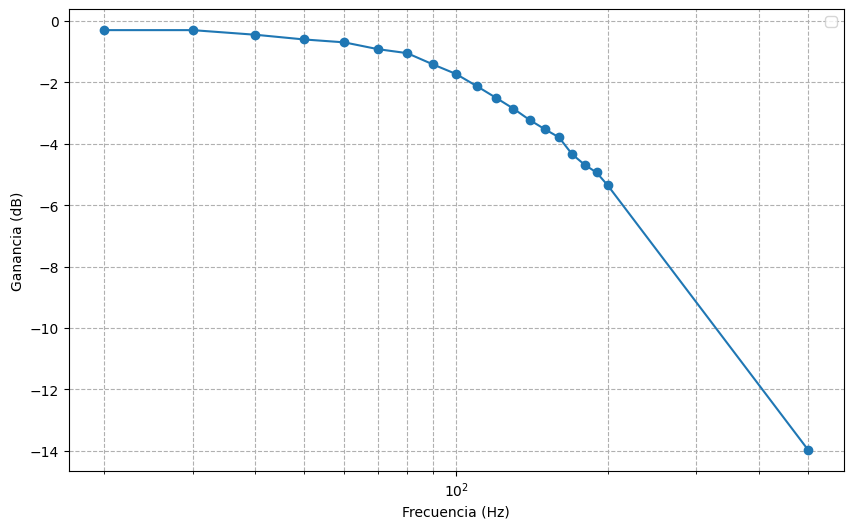

In [ ]:


freq_arr = np.array(lpt_f)
amp_arr = np.array(lpt_o)

vin = 3


gain_db = 20 * np.log10(amp_arr / vin)


plt.figure(figsize=(10, 6))
plt.semilogx(freq_arr, gain_db, marker='o', linestyle='-')



plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Ganancia (dB)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

##FIR

/tmp/ipykernel_1234/2064662454.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


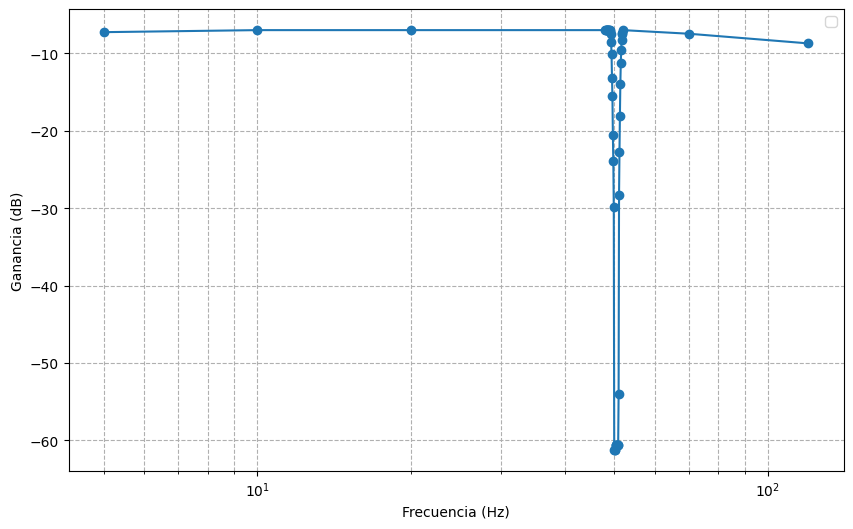

In [ ]:
freq_arr = np.array(fir_f)
amp_arr = np.array(fir_o)

vin = 3


gain_db = 20 * np.log10(amp_arr / vin)


plt.figure(figsize=(10, 6))
plt.semilogx(freq_arr, gain_db, marker='o', linestyle='-')



plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Ganancia (dB)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

##IIR

/tmp/ipykernel_1234/1430939511.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


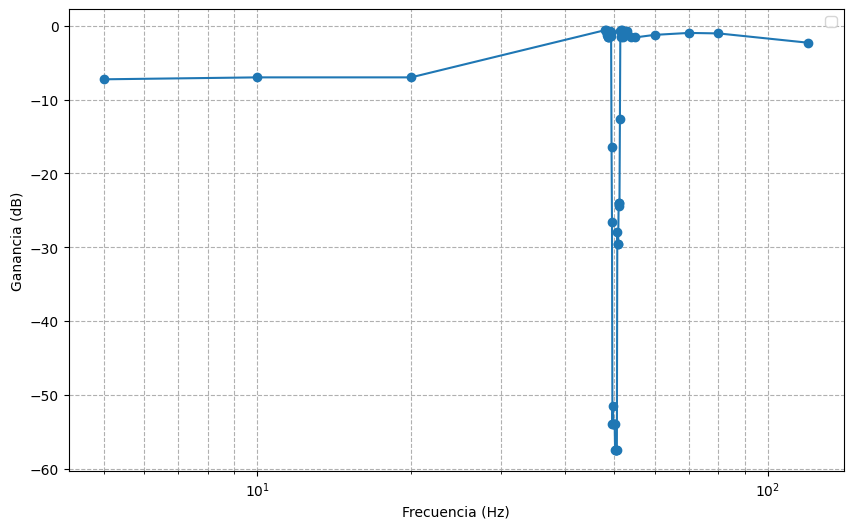

In [ ]:
freq_arr = np.array(iir_f)
amp_arr = np.array(iir_o)

vin = 3


gain_db = 20 * np.log10(amp_arr / vin)


plt.figure(figsize=(10, 6))
plt.semilogx(freq_arr, gain_db, marker='o', linestyle='-')



plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Ganancia (dB)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

Se puede observar que las mediciones coinciden con las simulaciones realizadas. Debido a los altos ordenes, intentar medir fase se vuelve ineficaz, porque no se pueden tomar intervalos lo suficientemente pequeños para poder realizar un trazado continuo.